# Cross-Sectional Return Prediction via Kernel Ridge Regression

We estimate a separate return-prediction function for each stock with Kernel Ridge Regression (KRR), comparing a linear kernel against polynomial and RBF (Gaussian) kernels. Predicted returns feed a regularized mean-variance portfolio, evaluated out-of-sample against the equal-weight (1/N) benchmark.

In [1]:
import numpy as np
import pandas as pd
from itertools import product
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt


the 10 characteristics

the historical window

the hyper-parameter grids

The target is next-month return (since we dont't have the actual return we approximate it as mom1m shifted by one month)

In [2]:
DATA_PATH = r"data/datashare.csv"       
START_DATE = pd.Timestamp("1990-01-31")
N_STOCKS = 50                        

FEATURES = ["mvel1", "bm", "mom12m", "chmom", "operprof","invest", "beta", "idiovol", "ill", "turn"]

# Hyper-parameter grids 
LAMBDA_GRID = np.logspace(-6, 6, 25)          # ridge penalty for the KRR
DEGREE_GRID = [2, 3]                          # polynomial kernel
COEF0_GRID  = [0.1, 1.0]                      # polynomial kernel (the "c")
GAMMA_GRID  = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2,
               3e-2, 1e-1, 3e-1, 1.0]         # RBF kernel bandwidth
MVE_GAMMA_GRID = np.logspace(-6, 4, 21)       # ridge for the covariance in the MVE step


## Load and prepare the data

We keep the 10 characteristics plus permno, DATE and mom1m, restrict the sample to the N_STOCKS largest stocks (by market equity mvel1) at the starting date, fill missing characteristics with the monthly cross-sectional median, and build the target RET as next month's return.

50 stocks without survivor bias

In [3]:
columns = ["DATE", "permno", "mom1m"] + FEATURES
df = pd.read_csv(DATA_PATH, usecols=columns)

df["DATE"] = pd.to_datetime(df["DATE"], format="%Y%m%d")
df = df[df["DATE"] >= START_DATE].copy()

# Universe: the N largest stocks (by market equity) at the first date
top = (df[df["DATE"] == START_DATE]
       .dropna(subset=["mvel1"])
       .nlargest(N_STOCKS, "mvel1")["permno"])
df = df[df["permno"].isin(top)].copy()
df = df.sort_values(["permno", "DATE"]).reset_index(drop=True)

# Fill missing characteristics with the monthly cross-sectional median
for col in FEATURES:
    df[col] = df[col].fillna(df.groupby("DATE")[col].transform("median"))

# Target = next-month return (mom1m shifted one month back); drop the last obs per stock
df["RET"] = df.groupby("permno")["mom1m"].shift(-1)
df = df.dropna(subset=["RET"]).drop(columns=["mom1m"])

df.head()


,permno,DATE,mvel1,beta,chmom,idiovol,mom12m,turn,bm,invest,operprof,ill,RET
0,10401,1990-01-31,48936706.00,0.564784,0.077800,0.031758,0.559758,0.338477,0.453543,0.041352,0.474752,1.822203e-10,-0.142857
1,10401,1990-02-28,41945748.00,0.597836,-0.340335,0.031118,0.490294,0.345582,0.453543,0.041352,0.474752,1.901775e-10,0.019231
2,10401,1990-03-30,42752397.00,0.677449,-0.346705,0.031581,0.330179,0.364362,0.453543,0.041352,0.474752,1.894478e-10,0.064906
3,10401,1990-04-30,45183516.00,0.677914,-0.496913,0.031105,0.289677,0.356381,0.453543,0.041352,0.474752,1.825628e-10,-0.044643
4,10401,1990-05-31,43166394.75,0.698891,-0.368318,0.030550,0.240476,0.258973,0.453543,0.041352,0.474752,2.178284e-10,0.074766


#### 50 stocks with survivor bias

## Cross-sectional standardization

Each characteristic is standardized within each month, to avoid data leackage (subtract the cross-sectional
mean, divide by the cross-sectional standard deviation). This uses only information available at time t, so it introduces no look-ahead bias, and it puts every characteristic on a comparable scale — which the kernel is sensitive to.

In [4]:
FEATURES_STD = []
for col in FEATURES:
    mean_m = df.groupby("DATE")[col].transform("mean")
    std_m  = df.groupby("DATE")[col].transform("std").replace(0, np.nan)
    std_col = col + "_std"
    df[std_col] = ((df[col] - mean_m) / std_m).fillna(0)  # constant month -> 0
    FEATURES_STD.append(std_col)


## Time-series split (60% / 20% / 20%)

In [5]:
dates = df["DATE"].drop_duplicates().sort_values().reset_index(drop=True)
n = len(dates)
train_dates      = dates.iloc[:int(0.60 * n)]
validation_dates = dates.iloc[int(0.60 * n):int(0.80 * n)]
test_dates       = dates.iloc[int(0.80 * n):]

train       = df[df["DATE"].isin(train_dates)].copy()
validation  = df[df["DATE"].isin(validation_dates)].copy()
test        = df[df["DATE"].isin(test_dates)].copy()
development  = pd.concat([train, validation], ignore_index=True)

for name, data in [("Training", train), ("Validation", validation), ("Test", test)]:
    print(f"{name:11s} | {data['DATE'].min().date()} - {data['DATE'].max().date()} "
          f"| months: {data['DATE'].nunique():3d} | obs: {len(data):5d} "
          f"| stocks: {data['permno'].nunique()}")


Training    | 1990-01-31 - 2009-01-30 | months: 229 | obs:  9911 | stocks: 50
Validation  | 2009-02-27 - 2015-06-30 | months:  77 | obs:  2357 | stocks: 33
Test        | 2015-07-31 - 2021-11-30 | months:  77 | obs:  2193 | stocks: 30


In [6]:
def make_krr(kernel, p):
    # Build a KernelRidge model from a parameter dict p.
    if kernel == "linear":
        return KernelRidge(alpha=p["lambda"], kernel="linear")
    if kernel == "polynomial":
        return KernelRidge(alpha=p["lambda"], kernel="polynomial",
                           gamma=1, degree=int(p["degree"]), coef0=p["c"])
    if kernel == "rbf":
        return KernelRidge(alpha=p["lambda"], kernel="rbf", gamma=p["gamma"])
    raise ValueError(kernel)


def _xy(data, permno):
    # Return (X, y) arrays for one stock, sorted by date.
    d = data[data["permno"] == permno].sort_values("DATE")
    return d[FEATURES_STD].to_numpy(), d["RET"].to_numpy()

    # For each stock, pick the parameter set with the lowest validation MSE.

def tune_kernel(kernel, param_grid):
    rows = []
    for permno in sorted(validation["permno"].unique()):
        X_tr, y_tr = _xy(train, permno)
        X_va, y_va = _xy(validation, permno)
        for p in param_grid:
            model = make_krr(kernel, p).fit(X_tr, y_tr)
            mse = mean_squared_error(y_va, model.predict(X_va))
            rows.append({"permno": permno, **p, "validation_mse": mse})

    results = pd.DataFrame(rows)
    best = (results.loc[results.groupby("permno")["validation_mse"].idxmin()]
                   .sort_values("permno").reset_index(drop=True))
    best["kernel"] = kernel
    return results, best


## Tune one KRR per stock, for each kernel

In [7]:
linear_grid     = [{"lambda": l} for l in LAMBDA_GRID]
polynomial_grid = [{"lambda": l, "degree": d, "c": c}
                   for l, d, c in product(LAMBDA_GRID, DEGREE_GRID, COEF0_GRID)]
rbf_grid        = [{"lambda": l, "gamma": g}
                   for l, g in product(LAMBDA_GRID, GAMMA_GRID)]

linear_results, best_linear = tune_kernel("linear", linear_grid)
polynomial_results, best_polynomial = tune_kernel("polynomial", polynomial_grid)
rbf_results, best_rbf = tune_kernel("rbf", rbf_grid)

print("Validation MSE by kernel (mean across stocks):")
for name, tbl in [("linear", best_linear),
                  ("polynomial", best_polynomial),
                  ("rbf", best_rbf)]:
    print(f"  {name:11s}: {tbl['validation_mse'].mean():.6f}")


Validation MSE by kernel (mean across stocks):
  linear     : 0.008305
  polynomial : 0.008118
  rbf        : 0.007817


## Best kernel per stock

Stacking the three tables and taking, for each tells us which kernel wins where. This best_model table is used for the
predictive-accuracy comparison with the next section.

In [8]:
cols = ["permno", "kernel", "lambda", "validation_mse"]
for tbl in (best_linear, best_polynomial, best_rbf):
    for c in ("degree", "c", "gamma"):
        if c not in tbl:
            tbl[c] = np.nan

model_comparison = pd.concat(
    [best_linear[cols + ["degree", "c", "gamma"]],
     best_polynomial[cols + ["degree", "c", "gamma"]],
     best_rbf[cols + ["degree", "c", "gamma"]]],
    ignore_index=True)

best_model = (model_comparison.loc[model_comparison.groupby("permno")["validation_mse"].idxmin()].sort_values("permno").reset_index(drop=True))

print("Kernel chosen per stock:")
print(best_model["kernel"].value_counts())


Kernel chosen per stock:
kernel
rbf           31
polynomial     2
Name: count, dtype: int64


## Out-of-sample predictive accuracy vs. the historical mean

For each stock we refit its chosen model on development and predict the test returns, then compare the squared error against a naive historical-mean forecast. The stock-level out-of-sample $R^2$ is $1 - \mathrm{MSE}_{KRR}/\mathrm{MSE}_{mean}$.

In [9]:
# Refit each stock's chosen model on fit_set and predict pred_set.
def predict_with_best(best_table, kernel, fit_set, pred_set, pred_col):
    out = []
    for permno in sorted(pred_set["permno"].unique()):
        info = best_table[best_table["permno"] == permno].iloc[0]
        X_fit, y_fit = _xy(fit_set, permno)
        d_pred = pred_set[pred_set["permno"] == permno].sort_values("DATE")
        X_pred = d_pred[FEATURES_STD].to_numpy()

        model = make_krr(kernel, info).fit(X_fit, y_fit)
        res = d_pred[["DATE", "permno", "RET"]].copy()
        res[pred_col] = model.predict(X_pred)
        out.append(res)
    return pd.concat(out, ignore_index=True)


# Predictions of each stock's best model (mixed kernels) on the test set
test_best = pd.concat(
    [predict_with_best(best_model[best_model["kernel"] == k], k,
                       development, test[test["permno"].isin(
                           best_model.loc[best_model["kernel"] == k, "permno"])],
                       "RET_PRED")
     for k in best_model["kernel"].unique()],
    ignore_index=True)

hist_mean = development.groupby("permno")["RET"].mean().rename("MEAN_FORECAST")
evaluation = test_best.merge(hist_mean, on="permno", how="left")

stock_metrics = (evaluation
    .assign(SQ_KRR=(evaluation["RET"] - evaluation["RET_PRED"]) ** 2,
            SQ_MEAN=(evaluation["RET"] - evaluation["MEAN_FORECAST"]) ** 2)
    .groupby("permno")
    .agg(mse_krr=("SQ_KRR", "mean"), mse_mean=("SQ_MEAN", "mean"))
    .reset_index())
stock_metrics["oos_r2"] = 1 - stock_metrics["mse_krr"] / stock_metrics["mse_mean"]
stock_metrics["krr_better"] = stock_metrics["mse_krr"] < stock_metrics["mse_mean"]

print("Stocks where KRR beats the historical mean:",
      int(stock_metrics["krr_better"].sum()), "/", len(stock_metrics))
print("Median stock-level OOS R^2:", round(stock_metrics["oos_r2"].median(), 4))


Stocks where KRR beats the historical mean: 11 / 30
Median stock-level OOS R^2: -0.0008


## Mean-variance portfolios

For each kernel we generate predictions for all stocks, estimate the return covariance $\Sigma$ on the in-sample block, and form the regularized mean-variance weights

$$w_t = (\Sigma + \gamma I)^{-1}\,\hat R_t,$$

rescaled to unit gross exposure ($\sum_i |w_i| = 1$). The single function mve_portfolio is used both to tune $\gamma$ on the validation set and to build the final test portfolios.

In [10]:
# Predictions of one kernel for every stock
def predict_all(best_table, kernel, fit_set, pred_set):
    return predict_with_best(best_table, kernel, fit_set, pred_set,
                             f"PRED_{kernel.upper()}")
    
def covariance(fit_set, stocks):
    wide = (fit_set[fit_set["permno"].isin(stocks)]
            .pivot(index="DATE", columns="permno", values="RET").sort_index())
    return wide.cov()

# Monthly mean-variance portfolio returns and weights.
def mve_portfolio(pred_df, pred_col, Sigma, gamma):
    ret_rows, w_rows = [], []
    for date, month in pred_df.groupby("DATE"):
        month = month.sort_values("permno")
        stocks = month["permno"].tolist()
        mu = month[pred_col].to_numpy()
        realized = month["RET"].to_numpy()
        cov = Sigma.loc[stocks, stocks].to_numpy()

        w = np.linalg.solve(cov + gamma * np.eye(len(stocks)), mu)
        gross = np.abs(w).sum()
        w = w / gross if gross > 0 else np.repeat(1 / len(stocks), len(stocks))

        ret_rows.append({"DATE": date, "portfolio_return": w @ realized})
        w_rows.extend({"DATE": date, "permno": s, "weight": wi}
                      for s, wi in zip(stocks, w))
    return pd.DataFrame(ret_rows), pd.DataFrame(w_rows)


## Tune the MVE ridge $\gamma$ on the validation set

For each kernel we clean $\gamma$ and keep the value that maximizes the validation annualized Sharpe ratio. Predictions are made by refitting on train and predicting validation; the covariance is estimated on train.

In [11]:
val_pred = (predict_all(best_linear, "linear", train, validation)
            .merge(predict_all(best_polynomial, "polynomial", train, validation)
                   [["DATE", "permno", "PRED_POLYNOMIAL"]], on=["DATE", "permno"])
            .merge(predict_all(best_rbf, "rbf", train, validation)
                   [["DATE", "permno", "PRED_RBF"]], on=["DATE", "permno"]))

Sigma_train = covariance(train, sorted(val_pred["permno"].unique()))

PRED_COL = {"linear": "PRED_LINEAR", "polynomial": "PRED_POLYNOMIAL", "rbf": "PRED_RBF"}

def annualized_sharpe(returns):
    vol = returns.std(ddof=1)
    return np.sqrt(12) * returns.mean() / vol if vol > 0 else np.nan

best_gamma = {}
for kernel, col in PRED_COL.items():
    scores = []
    for g in MVE_GAMMA_GRID:
        port, _ = mve_portfolio(val_pred, col, Sigma_train, g)
        scores.append((g, annualized_sharpe(port["portfolio_return"])))
    best_g = max(scores, key=lambda t: (t[1] if np.isfinite(t[1]) else -np.inf))[0]
    best_gamma[kernel] = best_g
    print(f"{kernel:11s} -> best gamma = {best_g:.4g}")


linear      -> best gamma = 1e+04
polynomial  -> best gamma = 1e+04
rbf         -> best gamma = 0.1


## Build the static test portfolios

The static test uses models fitted once on the development sample and one covariance matrix estimated on the same sample.

In [12]:
test_pred_static = (
    predict_all(best_linear, "linear", development, test)
    .merge(
        predict_all(best_polynomial, "polynomial", development, test)
        [["DATE", "permno", "PRED_POLYNOMIAL"]],
        on=["DATE", "permno"]
    )
    .merge(
        predict_all(best_rbf, "rbf", development, test)
        [["DATE", "permno", "PRED_RBF"]],
        on=["DATE", "permno"]
    )
)

Sigma_dev = covariance(development, sorted(test_pred_static["permno"].unique()))

portfolios_static = {}
weights_static = {}

for kernel, col in PRED_COL.items():

    port, w = mve_portfolio(
        test_pred_static,
        col,
        Sigma_dev,
        best_gamma[kernel]
    )

    portfolios_static[kernel] = port.rename(
        columns={"portfolio_return": f"RET_{kernel.upper()}"}
    )

    weights_static[kernel] = w


# 1/N benchmark
port_1n_static = (
    test_pred_static.groupby("DATE")["RET"]
    .mean()
    .rename("RET_1N")
    .reset_index()
)

# Merge every strategy on DATE
comparison_static = port_1n_static.copy()

for kernel in PRED_COL:

    ret_col = f"RET_{kernel.upper()}"

    comparison_static = comparison_static.merge(
        portfolios_static[kernel][["DATE", ret_col]],
        on="DATE"
    )

comparison_static = (
    comparison_static
    .sort_values("DATE")
    .reset_index(drop=True)
)

print("Static test completed.")
print("Test months used:", comparison_static["DATE"].nunique())
print("Test observations used:", len(test_pred_static))

comparison_static.head()


Static test completed.
Test months used: 77
Test observations used: 2193


,DATE,RET_1N,RET_LINEAR,RET_POLYNOMIAL,RET_RBF
0,2015-07-31,0.007592,-0.007450,0.001055,0.015870
1,2015-08-31,-0.062348,-0.059017,-0.056379,-0.040749
2,2015-09-30,-0.017557,-0.026041,-0.017599,-0.003141
3,2015-10-30,0.092914,0.121688,0.092512,0.051871
4,2015-11-30,-0.002416,0.003893,0.003100,0.003145


### Rolling-window test

The rolling-window test refits the KRR models and re-estimates the covariance matrix every month using only the previous 120 months.

In [13]:
# Rolling-window test predictions and portfolios

ROLLING_WINDOW_MONTHS = 120

test_pred_rolling_list = []

portfolio_parts_rolling = {
    "linear": [],
    "polynomial": [],
    "rbf": []
}

weight_parts_rolling = {
    "linear": [],
    "polynomial": [],
    "rbf": []
}

test_months = sorted(test["DATE"].unique())

for current_date in test_months:

    past_dates = (
        df.loc[df["DATE"] < current_date, "DATE"]
        .drop_duplicates()
        .sort_values()
    )

    window_dates = past_dates.iloc[-ROLLING_WINDOW_MONTHS:]

    fit_window = df[
        df["DATE"].isin(window_dates)
    ].copy()

    test_month = test[
        test["DATE"] == current_date
    ].copy()

    pred_month = (
        predict_all(best_linear, "linear", fit_window, test_month)
        .merge(
            predict_all(best_polynomial, "polynomial", fit_window, test_month)
            [["DATE", "permno", "PRED_POLYNOMIAL"]],
            on=["DATE", "permno"]
        )
        .merge(
            predict_all(best_rbf, "rbf", fit_window, test_month)
            [["DATE", "permno", "PRED_RBF"]],
            on=["DATE", "permno"]
        )
    )

    if len(pred_month) == 0:
        continue

    stocks = sorted(pred_month["permno"].unique())

    Sigma_roll = covariance(fit_window, stocks)

    valid_stocks = [
        s for s in Sigma_roll.index
        if (not Sigma_roll.loc[s].isna().any())
        and (not Sigma_roll[s].isna().any())
    ]

    pred_month = pred_month[
        pred_month["permno"].isin(valid_stocks)
    ].copy()

    Sigma_roll = Sigma_roll.loc[
        valid_stocks,
        valid_stocks
    ]

    if len(pred_month) == 0:
        continue

    test_pred_rolling_list.append(pred_month)

    for kernel, col in PRED_COL.items():

        port, w = mve_portfolio(
            pred_month,
            col,
            Sigma_roll,
            best_gamma[kernel]
        )

        port = port.rename(
            columns={"portfolio_return": f"RET_{kernel.upper()}"}
        )

        portfolio_parts_rolling[kernel].append(port)
        weight_parts_rolling[kernel].append(w)


test_pred_rolling = (
    pd.concat(test_pred_rolling_list, ignore_index=True)
    .sort_values(["DATE", "permno"])
    .reset_index(drop=True)
)

portfolios_rolling = {}
weights_rolling = {}

for kernel in PRED_COL:

    portfolios_rolling[kernel] = (
        pd.concat(portfolio_parts_rolling[kernel], ignore_index=True)
        .sort_values("DATE")
        .reset_index(drop=True)
    )

    weights_rolling[kernel] = (
        pd.concat(weight_parts_rolling[kernel], ignore_index=True)
        .sort_values(["DATE", "permno"])
        .reset_index(drop=True)
    )


# 1/N benchmark on the same rolling test observations
port_1n_rolling = (
    test_pred_rolling.groupby("DATE")["RET"]
    .mean()
    .rename("RET_1N")
    .reset_index()
)

# Merge every strategy on DATE
comparison_rolling = port_1n_rolling.copy()

for kernel in PRED_COL:

    ret_col = f"RET_{kernel.upper()}"

    comparison_rolling = comparison_rolling.merge(
        portfolios_rolling[kernel][["DATE", ret_col]],
        on="DATE"
    )

comparison_rolling = (
    comparison_rolling
    .sort_values("DATE")
    .reset_index(drop=True)
)

print("Rolling-window test completed.")
print("Test months used:", comparison_rolling["DATE"].nunique())
print("Test observations used:", len(test_pred_rolling))

comparison_rolling.head()


Rolling-window test completed.
Test months used: 77
Test observations used: 2193


,DATE,RET_1N,RET_LINEAR,RET_POLYNOMIAL,RET_RBF
0,2015-07-31,0.007592,-0.022363,0.009545,0.016216
1,2015-08-31,-0.062348,-0.058615,-0.055269,-0.041999
2,2015-09-30,-0.017557,-0.006387,-0.011502,-0.003517
3,2015-10-30,0.092914,0.117465,0.026385,0.030397
4,2015-11-30,-0.002416,0.005780,0.007485,0.004725


## Out-of-sample performance

The following tables report the static specification and the rolling-window specification separately.

In [14]:
def portfolio_metrics(returns):

    returns = returns.dropna()

    ann_ret = returns.mean() * 12
    ann_vol = returns.std(ddof=1) * np.sqrt(12)

    wealth = (1 + returns).cumprod()
    drawdown = wealth / wealth.cummax() - 1

    return {
        "annualized_return": ann_ret,
        "annualized_volatility": ann_vol,
        "sharpe_ratio": ann_ret / ann_vol if ann_vol > 0 else np.nan,
        "max_drawdown": drawdown.min(),
        "final_wealth": wealth.iloc[-1],
    }


STRATEGIES = {
    "1/N": "RET_1N",
    "Linear KRR-MVE": "RET_LINEAR",
    "Polynomial KRR-MVE": "RET_POLYNOMIAL",
    "RBF KRR-MVE": "RET_RBF"
}


performance_static = (
    pd.DataFrame({
        name: portfolio_metrics(comparison_static[col])
        for name, col in STRATEGIES.items()
    })
    .T
)

performance_rolling = (
    pd.DataFrame({
        name: portfolio_metrics(comparison_rolling[col])
        for name, col in STRATEGIES.items()
    })
    .T
)

print("Static specification")
display(performance_static.round(4))

print("Rolling-window specification")
display(performance_rolling.round(4))


Static specification


,annualized_return,annualized_volatility,sharpe_ratio,max_drawdown,final_wealth
1/N,0.1016,0.1430,0.7106,-0.2376,1.7945
Linear KRR-MVE,0.0709,0.1176,0.6031,-0.1686,1.5070
Polynomial KRR-MVE,0.0184,0.1190,0.1549,-0.1870,1.0762
RBF KRR-MVE,0.0393,0.1035,0.3797,-0.1876,1.2434


Rolling-window specification


,annualized_return,annualized_volatility,sharpe_ratio,max_drawdown,final_wealth
1/N,0.1016,0.1430,0.7106,-0.2376,1.7945
Linear KRR-MVE,0.0807,0.1146,0.7043,-0.1221,1.6080
Polynomial KRR-MVE,0.0538,0.1247,0.4314,-0.1669,1.3429
RBF KRR-MVE,0.0500,0.1138,0.4396,-0.1619,1.3239


## Cumulative wealth

The first plot refers to the static specification. The second plot refers to the rolling-window specification.

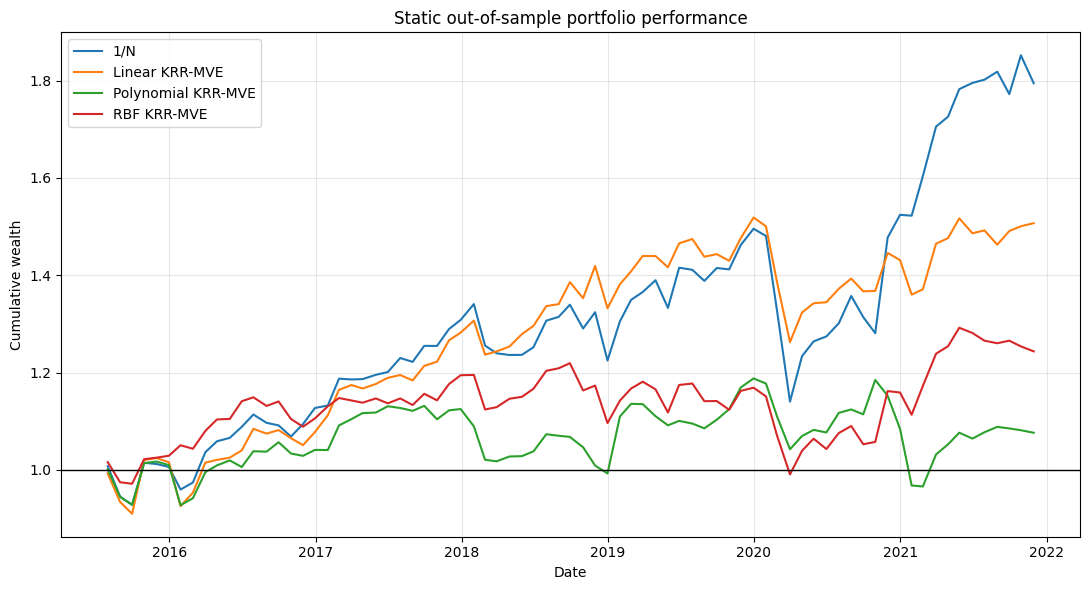

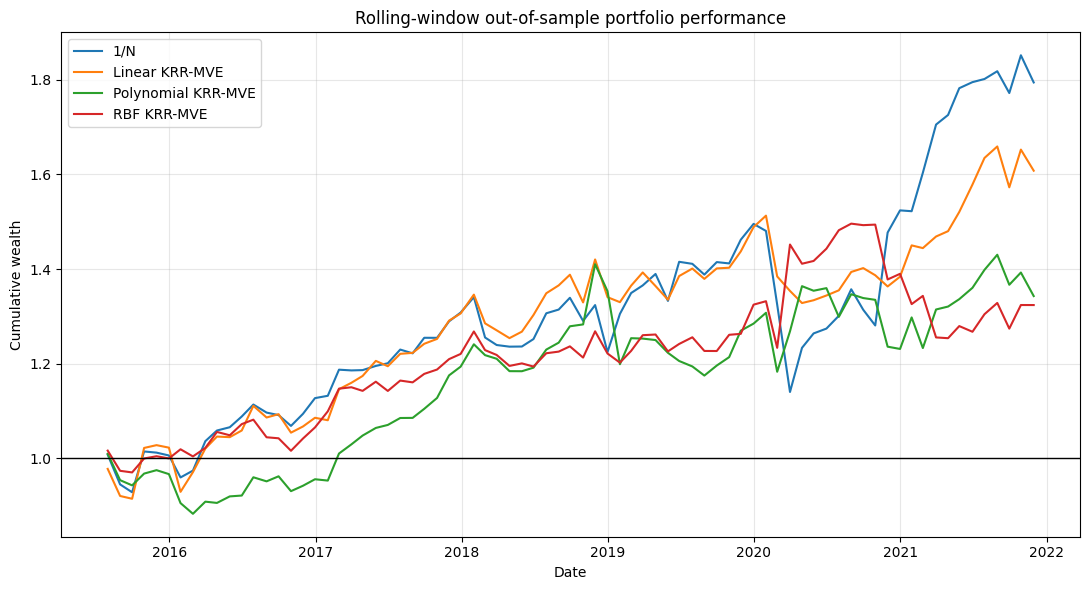

In [15]:
plt.figure(figsize=(11, 6))

for name, col in STRATEGIES.items():

    plt.plot(
        comparison_static["DATE"],
        (1 + comparison_static[col]).cumprod(),
        label=name
    )

plt.axhline(1, linewidth=1, color="black")
plt.xlabel("Date")
plt.ylabel("Cumulative wealth")
plt.title("Static out-of-sample portfolio performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cumulative_wealth_static.png", dpi=300)
plt.show()


plt.figure(figsize=(11, 6))

for name, col in STRATEGIES.items():

    plt.plot(
        comparison_rolling["DATE"],
        (1 + comparison_rolling[col]).cumprod(),
        label=name
    )

plt.axhline(1, linewidth=1, color="black")
plt.xlabel("Date")

plt.ylabel("Cumulative wealth")
plt.title("Rolling-window out-of-sample portfolio performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cumulative_wealth_rolling.png", dpi=300)
plt.show()




## Weight descriptive statistics

The following tables report weight diagnostics for both the static and rolling-window specifications.

In [16]:
def weight_diagnostics(w_df):

    wide = (
        w_df.pivot(index="DATE", columns="permno", values="weight")
        .fillna(0)
        .sort_index()
    )

    turnover = wide.diff().abs().sum(axis=1) / 2

    return {
        "avg_gross_exposure": wide.abs().sum(axis=1).mean(),
        "avg_net_exposure": wide.sum(axis=1).mean(),
        "avg_concentration": wide.pow(2).sum(axis=1).mean(),
        "avg_max_abs_weight": wide.abs().max(axis=1).mean(),
        "avg_monthly_turnover": turnover.mean(),
    }


# 1/N weights for reference
w_1n_static = test_pred_static[["DATE", "permno"]].copy()
w_1n_static["weight"] = (
    1 / test_pred_static.groupby("DATE")["permno"].transform("count")
)

w_1n_rolling = test_pred_rolling[["DATE", "permno"]].copy()
w_1n_rolling["weight"] = (
    1 / test_pred_rolling.groupby("DATE")["permno"].transform("count")
)


weight_sets_static = {
    "1/N": w_1n_static,
    "Linear KRR-MVE": weights_static["linear"],
    "Polynomial KRR-MVE": weights_static["polynomial"],
    "RBF KRR-MVE": weights_static["rbf"]
}

weight_sets_rolling = {
    "1/N": w_1n_rolling,
    "Linear KRR-MVE": weights_rolling["linear"],
    "Polynomial KRR-MVE": weights_rolling["polynomial"],
    "RBF KRR-MVE": weights_rolling["rbf"]
}


weight_diagnostics_static = (
    pd.DataFrame({
        name: weight_diagnostics(w)
        for name, w in weight_sets_static.items()
    })
    .T
)

weight_diagnostics_rolling = (
    pd.DataFrame({
        name: weight_diagnostics(w)
        for name, w in weight_sets_rolling.items()
    })
    .T
)

print("Static specification")
display(weight_diagnostics_static.round(4))

print("Rolling-window specification")
display(weight_diagnostics_rolling.round(4))


Static specification


,avg_gross_exposure,avg_net_exposure,avg_concentration,avg_max_abs_weight,avg_monthly_turnover
1/N,1.0,1.0000,0.0352,0.0352,0.0013
Linear KRR-MVE,1.0,0.6153,0.0897,0.1741,0.1426
Polynomial KRR-MVE,1.0,0.4976,0.1248,0.2442,0.1909
RBF KRR-MVE,1.0,0.5906,0.0619,0.1441,0.1436


Rolling-window specification


,avg_gross_exposure,avg_net_exposure,avg_concentration,avg_max_abs_weight,avg_monthly_turnover
1/N,1.0,1.0000,0.0352,0.0352,0.0013
Linear KRR-MVE,1.0,0.8095,0.1033,0.2088,0.2093
Polynomial KRR-MVE,1.0,0.6861,0.1106,0.2289,0.2921
RBF KRR-MVE,1.0,0.5752,0.0818,0.1830,0.3587


## Forecast accuracy per kernel

The following tables report test MSE, RMSE and MAE for both the static and rolling-window specifications.

In [17]:
def forecast_accuracy(pred_df):

    rows = []

    forecast_columns = {
        "Linear": "PRED_LINEAR",
        "Polynomial": "PRED_POLYNOMIAL",
        "RBF": "PRED_RBF"
    }

    for model, col in forecast_columns.items():

        error = pred_df["RET"] - pred_df[col]

        rows.append({
            "model": model,
            "test_mse": np.mean(error ** 2),
            "test_rmse": np.sqrt(np.mean(error ** 2)),
            "test_mae": np.mean(np.abs(error))
        })

    return pd.DataFrame(rows)


forecast_accuracy_static = forecast_accuracy(test_pred_static)
forecast_accuracy_rolling = forecast_accuracy(test_pred_rolling)

print("Static specification")
display(forecast_accuracy_static.round(6))

print("Rolling-window specification")
display(forecast_accuracy_rolling.round(6))


Static specification


,model,test_mse,test_rmse,test_mae
0,Linear,0.005134,0.071649,0.050385
1,Polynomial,0.005261,0.072532,0.051131
2,RBF,0.005220,0.072252,0.051057


Rolling-window specification


,model,test_mse,test_rmse,test_mae
0,Linear,0.005122,0.071571,0.050234
1,Polynomial,0.005187,0.072020,0.050625
2,RBF,0.005421,0.073626,0.051478


## SENSITIVITY ANALYSIS

In [18]:
BEST_KRR = {"Linear": best_linear,"Polynomial": best_polynomial,"RBF": best_rbf}

KRR_TUNING_RESULTS = {"Linear": linear_results, "Polynomial": polynomial_results,"RBF": rbf_results}


In [19]:
# Selected lambda values

lambda_selected = []

for kernel, table in BEST_KRR.items():

    temp = table[["permno", "lambda", "validation_mse"]].copy()
    temp["kernel"] = kernel

    lambda_selected.append(temp)

lambda_selected = pd.concat(lambda_selected, ignore_index=True)

lambda_summary = (
    lambda_selected
    .groupby("kernel")
    .agg(
        mean_lambda=("lambda", "mean"),
        median_lambda=("lambda", "median"),
        min_lambda=("lambda", "min"),
        max_lambda=("lambda", "max"),
        mean_validation_mse=("validation_mse", "mean")
    )
)

lambda_summary.round(6)

# Lambda frequency by kernel

lambda_frequency = (
    lambda_selected
    .groupby(["kernel", "lambda"])
    .size()
    .rename("n_stocks")
    .reset_index()
    .sort_values(["kernel", "lambda"])
)

# Validation MSE by lambda

lambda_sensitivity = []

for kernel, table in KRR_TUNING_RESULTS.items():

    temp = (
        table
        .groupby("lambda")
        .agg(
            avg_validation_mse=("validation_mse", "mean"),
            median_validation_mse=("validation_mse", "median"),
            n_models=("validation_mse", "size")
        )
        .reset_index()
    )

    temp["kernel"] = kernel

    lambda_sensitivity.append(temp)

lambda_sensitivity = (
    pd.concat(lambda_sensitivity, ignore_index=True)
    .sort_values(["kernel", "lambda"])
    .reset_index(drop=True)
)

lambda_sensitivity.head()


,lambda,avg_validation_mse,median_validation_mse,n_models,kernel
0,0.000001,0.010643,0.003349,33,Linear
1,0.000003,0.010643,0.003349,33,Linear
2,0.000010,0.010643,0.003349,33,Linear
3,0.000032,0.010643,0.003349,33,Linear
4,0.000100,0.010643,0.003349,33,Linear


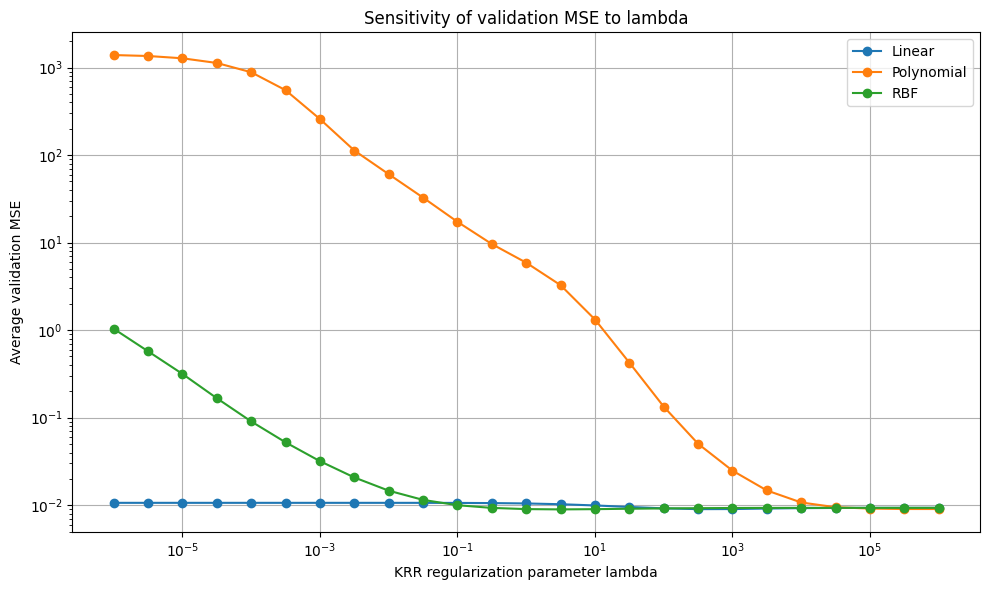

In [27]:
# Plot validation MSE against lambda

plt.figure(figsize=(10, 6))

for kernel in ["Linear", "Polynomial", "RBF"]:

    temp = lambda_sensitivity[
        lambda_sensitivity["kernel"] == kernel
    ].copy()

    plt.plot(
        temp["lambda"],
        temp["avg_validation_mse"],
        marker="o",
        label=kernel
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel("KRR regularization parameter lambda")
plt.ylabel("Average validation MSE")
plt.title("Sensitivity of validation MSE to lambda")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("lambda_sensitivity_validation_mse.png", dpi=300)
plt.show()


In [21]:
# Sensitivity to MVE gamma
MVE_GAMMA_SENSITIVITY_GRID = np.logspace(-6, 4, 11)

SENSITIVITY_KERNEL = "rbf"
SENSITIVITY_PRED_COL = PRED_COL[SENSITIVITY_KERNEL]


In [22]:
def rolling_mve_gamma_sensitivity(
    test_pred,
    full_data,
    pred_col,
    gamma_grid,
    rolling_window_months
):
    rows = []

    for gamma_value in gamma_grid:

        monthly_returns = []

        for current_date in sorted(test_pred["DATE"].unique()):

            past_dates = (
                full_data.loc[full_data["DATE"] < current_date, "DATE"]
                .drop_duplicates()
                .sort_values()
            )

            window_dates = past_dates.iloc[-rolling_window_months:]

            fit_window = full_data[
                full_data["DATE"].isin(window_dates)
            ].copy()

            month = test_pred[
                test_pred["DATE"] == current_date
            ].copy()

            stocks = sorted(month["permno"].unique())

            Sigma_roll = covariance(fit_window, stocks)

            valid_stocks = [
                s for s in Sigma_roll.index
                if (not Sigma_roll.loc[s].isna().any())
                and (not Sigma_roll[s].isna().any())
            ]

            month = month[
                month["permno"].isin(valid_stocks)
            ].copy()

            Sigma_roll = Sigma_roll.loc[
                valid_stocks,
                valid_stocks
            ]

            if len(month) == 0:
                continue

            port, _ = mve_portfolio(
                month,
                pred_col,
                Sigma_roll,
                gamma_value
            )

            monthly_returns.append(port)

        portfolio_gamma = (
            pd.concat(monthly_returns, ignore_index=True)
            .sort_values("DATE")
            .reset_index(drop=True)
        )

        metrics = portfolio_metrics(
            portfolio_gamma["portfolio_return"]
        )

        rows.append({
            "gamma": gamma_value,
            "annualized_return": metrics["annualized_return"],
            "annualized_volatility": metrics["annualized_volatility"],
            "sharpe_ratio": metrics["sharpe_ratio"],
            "max_drawdown": metrics["max_drawdown"],
            "final_wealth": metrics["final_wealth"],
            "n_months": portfolio_gamma["DATE"].nunique()
        })

    return pd.DataFrame(rows)


In [23]:
gamma_sensitivity = rolling_mve_gamma_sensitivity(
    test_pred=test_pred_rolling,
    full_data=df,
    pred_col=SENSITIVITY_PRED_COL,
    gamma_grid=MVE_GAMMA_SENSITIVITY_GRID,
    rolling_window_months=ROLLING_WINDOW_MONTHS
)

gamma_sensitivity


,gamma,annualized_return,annualized_volatility,sharpe_ratio,max_drawdown,final_wealth,n_months
0,0.000001,0.014815,0.050383,0.294052,-0.126709,1.090886,77
1,0.000010,0.014806,0.050686,0.292114,-0.127448,1.090717,77
2,0.000100,0.014782,0.053350,0.277084,-0.133489,1.089598,77
3,0.001000,0.016609,0.067113,0.247479,-0.160223,1.096698,77
4,0.010000,0.026608,0.088273,0.301426,-0.186762,1.157303,77
5,0.100000,0.050021,0.113776,0.439639,-0.161871,1.323938,77
6,1.000000,0.060947,0.126362,0.482319,-0.145457,1.407440,77
7,10.000000,0.062103,0.128056,0.484965,-0.143491,1.416159,77
8,100.000000,0.062219,0.128229,0.485216,-0.143290,1.417032,77
9,1000.000000,0.062230,0.128246,0.485240,-0.143270,1.417118,77


In [24]:
print(
    gamma_sensitivity.to_string(
        index=False,
        formatters={
            "gamma": "{:.0e}".format,
            "annualized_return": "{:.4f}".format,
            "annualized_volatility": "{:.4f}".format,
            "sharpe_ratio": "{:.4f}".format,
            "max_drawdown": "{:.4f}".format,
            "final_wealth": "{:.4f}".format,
            "n_months": "{:.0f}".format
        }
    )
)


gamma annualized_return annualized_volatility sharpe_ratio max_drawdown final_wealth n_months
1e-06            0.0148                0.0504       0.2941      -0.1267       1.0909       77
1e-05            0.0148                0.0507       0.2921      -0.1274       1.0907       77
1e-04            0.0148                0.0533       0.2771      -0.1335       1.0896       77
1e-03            0.0166                0.0671       0.2475      -0.1602       1.0967       77
1e-02            0.0266                0.0883       0.3014      -0.1868       1.1573       77
1e-01            0.0500                0.1138       0.4396      -0.1619       1.3239       77
1e+00            0.0609                0.1264       0.4823      -0.1455       1.4074       77
1e+01            0.0621                0.1281       0.4850      -0.1435       1.4162       77
1e+02            0.0622                0.1282       0.4852      -0.1433       1.4170       77
1e+03            0.0622                0.1282       0.4852  

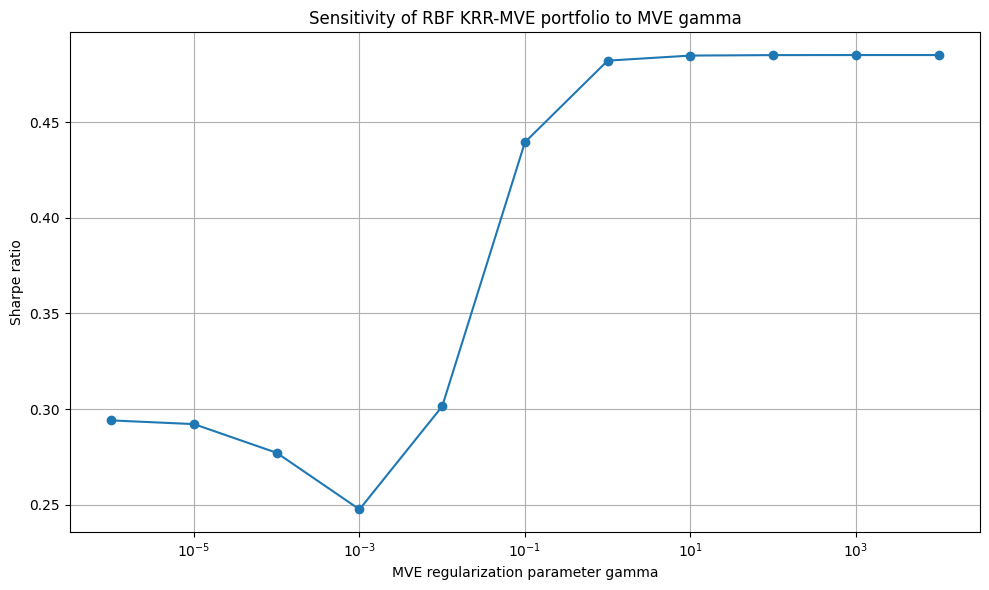

In [25]:
# Plot Sharpe ratio against MVE gamma

plt.figure(figsize=(10, 6))

plt.plot(
    gamma_sensitivity["gamma"],
    gamma_sensitivity["sharpe_ratio"],
    marker="o"
)

plt.xscale("log")
plt.xlabel("MVE regularization parameter gamma")
plt.ylabel("Sharpe ratio")
plt.title("Sensitivity of RBF KRR-MVE portfolio to MVE gamma")
plt.grid(True)
plt.tight_layout()
plt.savefig("mve_gamma_sensitivity_sharpe.png", dpi=300)
plt.show()


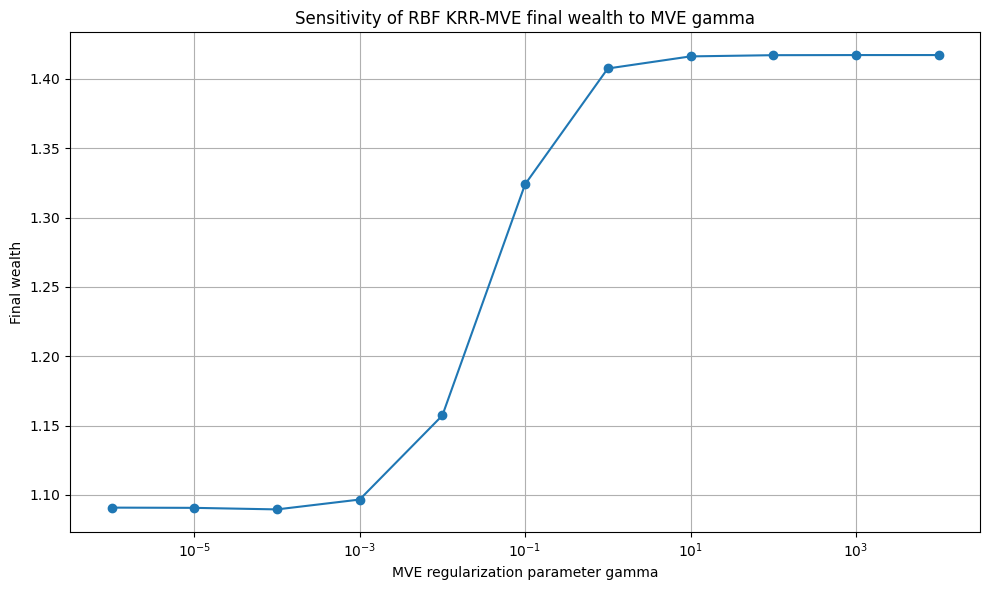

In [26]:
# Plot final wealth against MVE gamma

plt.figure(figsize=(10, 6))

plt.plot(
    gamma_sensitivity["gamma"],
    gamma_sensitivity["final_wealth"],
    marker="o"
)

plt.xscale("log")
plt.xlabel("MVE regularization parameter gamma")
plt.ylabel("Final wealth")
plt.title("Sensitivity of RBF KRR-MVE final wealth to MVE gamma")
plt.grid(True)
plt.tight_layout()
plt.savefig("mve_gamma_sensitivity_final_wealth.png", dpi=300)
plt.show()
